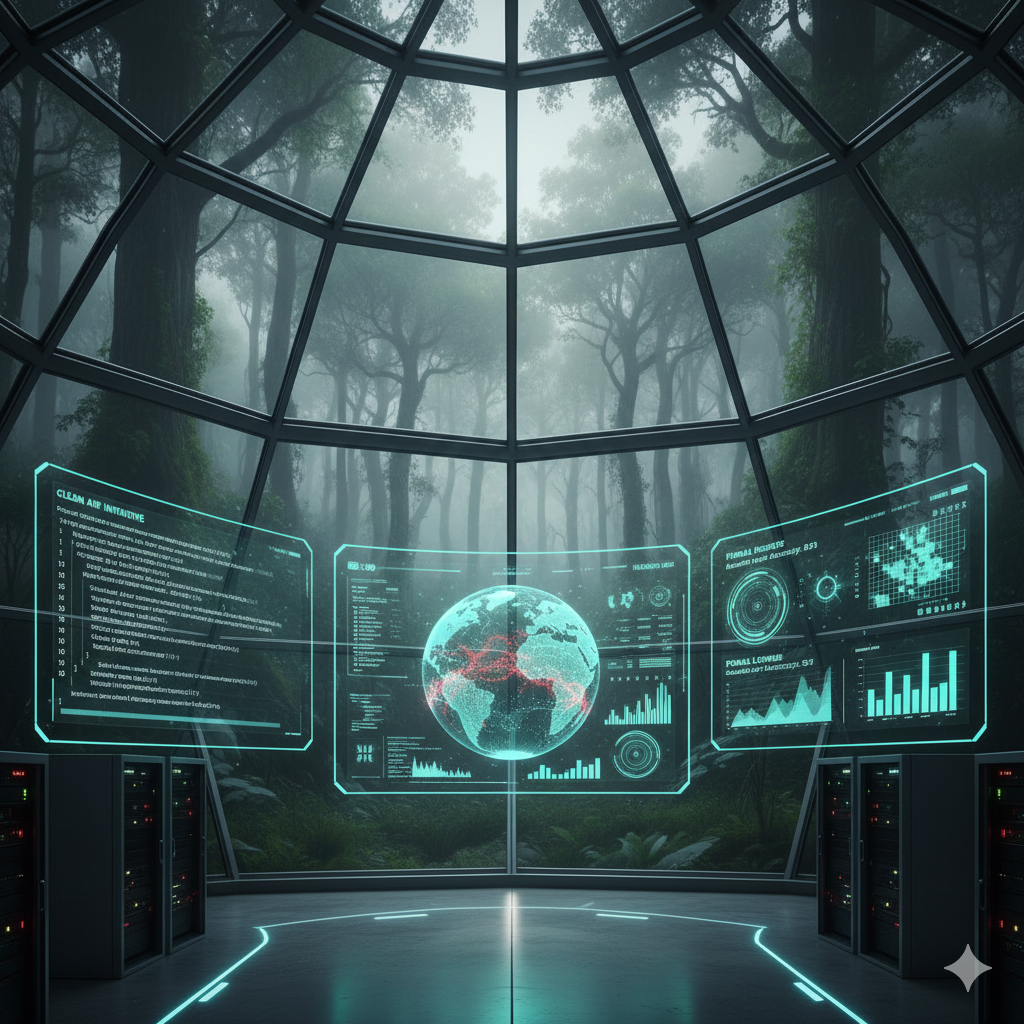

In [42]:
from IPython.display import Image, display

display(Image(filename=r"C:\Users\hp\Downloads\Gemini_Generated_Image_u5624au5624au562.png"))


In [1]:
import pandas as pd 
df = pd.read_csv(r"C:\Users\hp\Downloads\3b01bcb8-0b14-4abf-b6f2-c1bfd384ba69 (4).csv")


In [2]:
df.columns





Index(['country', 'state', 'city', 'station', 'last_update', 'latitude',
       'longitude', 'pollutant_id', 'pollutant_min', 'pollutant_max',
       'pollutant_avg'],
      dtype='object')

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Handle missing values
df.fillna(df.mean(numeric_only=True), inplace=True)

# Encode categorical data
df_encoded = pd.get_dummies(df, drop_first=True)




# Preliminary regression check
X = df_encoded.drop("pollutant_avg", axis=1)
y = df_encoded["pollutant_avg"]

X_train, X_test, y_train, y_test = train_test_split(X, y)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, pred))
print("RMSE:", mean_squared_error(y_test, pred))
print("R²:", r2_score(y_test, pred))




MAE: 12.432715466151672
RMSE: 379.7607623504139
R²: 0.9452368502098178


In [4]:
%matplotlib inline


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns


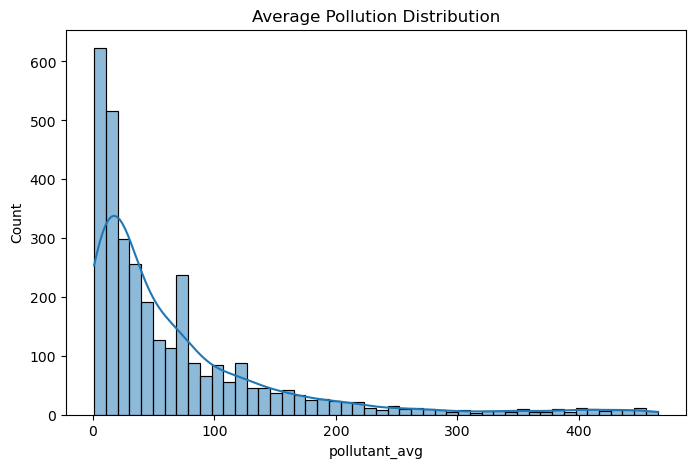

In [12]:
plt.figure(figsize=(8,5))
sns.histplot(df['pollutant_avg'], kde=True)
plt.title("Average Pollution Distribution")
plt.show()


<Figure size 640x480 with 0 Axes>

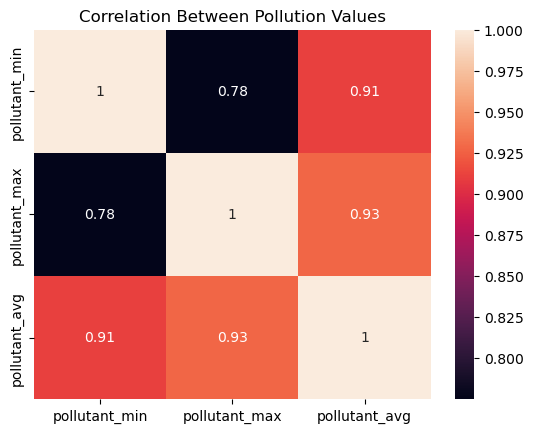

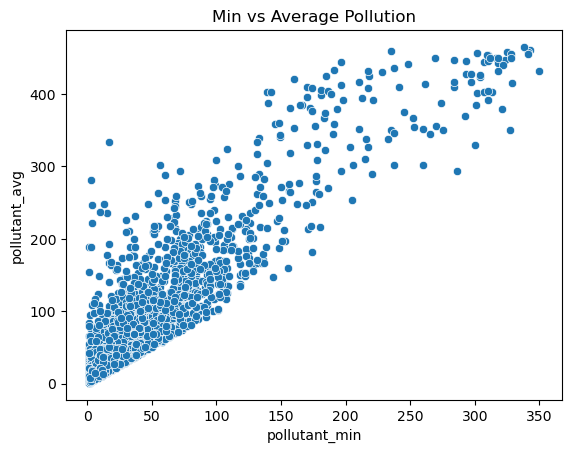

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

# Correlation Heatmap
plt.figure()
sns.heatmap(df[['pollutant_min','pollutant_max','pollutant_avg']].corr(), annot=True)
plt.title("Correlation Between Pollution Values")
plt.show()

# Scatter plot
plt.figure()
sns.scatterplot(x='pollutant_min', y='pollutant_avg', data=df)
plt.title("Min vs Average Pollution")
plt.show()


Linear Regression RMSE:     20.0827
Polynomial Regression RMSE: 19.5235


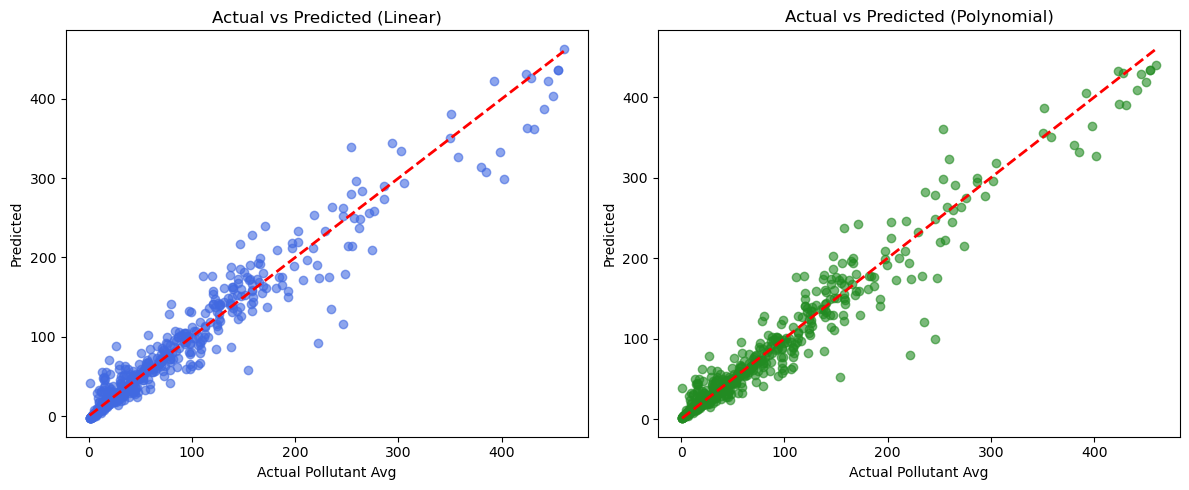

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split

# --- 1. Data Loading ---
# Replace this with your actual loading method (e.g., df = pd.read_csv('data.csv'))
# Assuming 'df' is already defined in your environment:
X = df[['pollutant_min', 'pollutant_max']]
y = df['pollutant_avg']

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# --- 2. Linear Regression ---
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
pred_lr = lr_model.predict(X_test)

# --- 3. Polynomial Regression (Degree 2) ---
poly_features = PolynomialFeatures(degree=2)
X_train_poly = poly_features.fit_transform(X_train)
X_test_poly = poly_features.transform(X_test)

poly_lr_model = LinearRegression()
poly_lr_model.fit(X_train_poly, y_train)
pred_poly = poly_lr_model.predict(X_test_poly)

# --- 4. Evaluation (Updated to avoid FutureWarning) ---
# Using the specific RMSE function available in Scikit-Learn 1.4+
rmse_linear = root_mean_squared_error(y_test, pred_lr)
rmse_poly = root_mean_squared_error(y_test, pred_poly)

print(f"Linear Regression RMSE:     {rmse_linear:.4f}")
print(f"Polynomial Regression RMSE: {rmse_poly:.4f}")

# --- 5. Visualization ---
plt.figure(figsize=(12, 5))

# Plot Linear Results
plt.subplot(1, 2, 1)
plt.scatter(y_test, pred_lr, alpha=0.6, color='royalblue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title("Actual vs Predicted (Linear)")
plt.xlabel("Actual Pollutant Avg")
plt.ylabel("Predicted")

# Plot Polynomial Results
plt.subplot(1, 2, 2)
plt.scatter(y_test, pred_poly, alpha=0.6, color='forestgreen')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.title("Actual vs Predicted (Polynomial)")
plt.xlabel("Actual Pollutant Avg")
plt.ylabel("Predicted")

plt.tight_layout()
plt.show()

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.94      0.94       355
           1       0.73      0.70      0.72       141
           2       0.87      0.90      0.89       155

    accuracy                           0.88       651
   macro avg       0.85      0.85      0.85       651
weighted avg       0.88      0.88      0.88       651



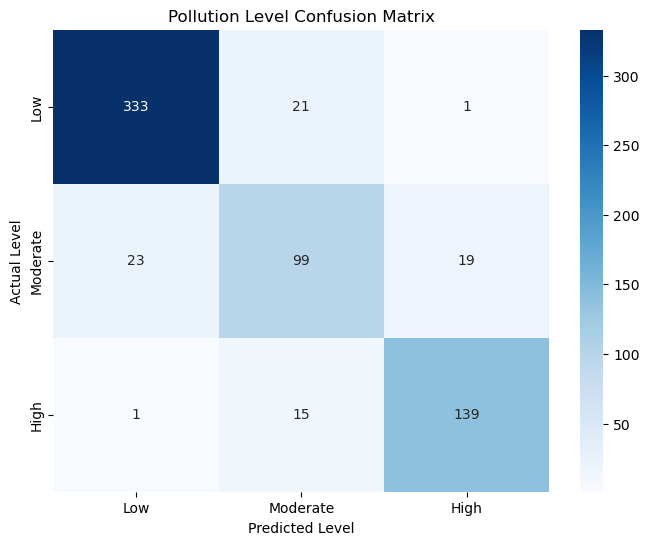

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

# 1. Create target classes based on the new column name 'pollutant_avg'
def pollution_level(avg):
    if avg <= 50:
        return 0  # Low
    elif avg <= 100:
        return 1  # Moderate
    else:
        return 2  # High

df['Pollution_Level'] = df['pollutant_avg'].apply(pollution_level)

# 2. Define Features and Target using updated column names
X = df[['pollutant_min', 'pollutant_max']]
y = df['Pollution_Level']

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Initialize and Train Decision Tree
model = DecisionTreeClassifier(random_state=42)
model.fit(X_train, y_train)

# 5. Predict
y_pred = model.predict(X_test)

# 6. Print Metrics
print("Classification Report:")
print(classification_report(y_test, y_pred))

# 7. Visualize Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=['Low', 'Moderate', 'High'], 
            yticklabels=['Low', 'Moderate', 'High'])
plt.xlabel("Predicted Level")
plt.ylabel("Actual Level")
plt.title("Pollution Level Confusion Matrix")
plt.show()

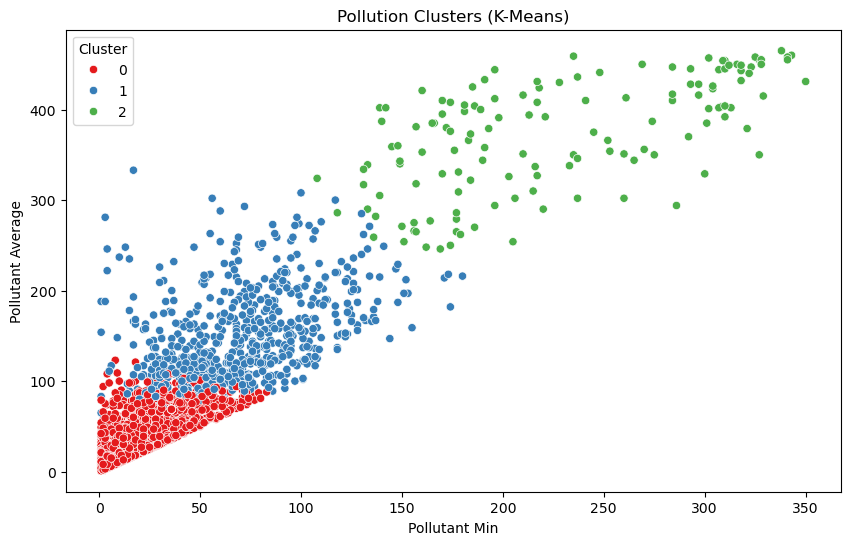

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# 1. Scale the data using updated column names
scaler = StandardScaler()
# Using the corrected column names
cols_to_scale = ['pollutant_min', 'pollutant_max', 'pollutant_avg']
scaled_data = scaler.fit_transform(df[cols_to_scale])

# 2. Initialize and fit KMeans
# n_init='auto' suppresses warnings in newer sklearn versions
kmeans = KMeans(n_clusters=3, n_init='auto', random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled_data)

# 3. Visualization
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df, 
    x='pollutant_min', 
    y='pollutant_avg', 
    hue='Cluster', 
    palette='Set1'
)

plt.title("Pollution Clusters (K-Means)")
plt.xlabel("Pollutant Min")
plt.ylabel("Pollutant Average")
plt.show()

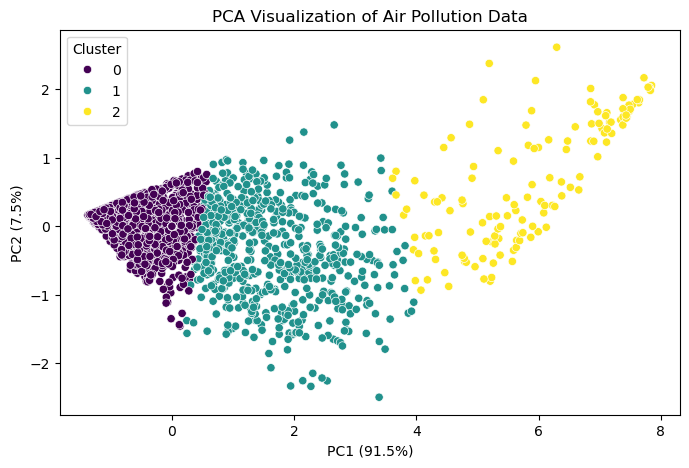

Total Explained Variance: 98.97%


In [32]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Scale features
features = ['pollutant_min', 'pollutant_max', 'pollutant_avg']
X_scaled = StandardScaler().fit_transform(df[features])

# Apply PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Prepare DataFrame
pca_df = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
if 'Cluster' in df:
    pca_df['Cluster'] = df['Cluster']

# Plot
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=pca_df, x='PC1', y='PC2',
    hue='Cluster' if 'Cluster' in pca_df else None,
    palette='viridis'
)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.title("PCA Visualization of Air Pollution Data")
plt.show()

# Explained variance
print("Total Explained Variance:",
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")


In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

rf = RandomForestClassifier()
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

mlp = MLPClassifier(max_iter=500)
mlp.fit(X_train, y_train)
mlp_pred = mlp.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print("MLP Accuracy:", accuracy_score(y_test, mlp_pred))


Random Forest Accuracy: 0.9078341013824884
MLP Accuracy: 0.869431643625192


Cross Validation Accuracy: 0.9059307574146285


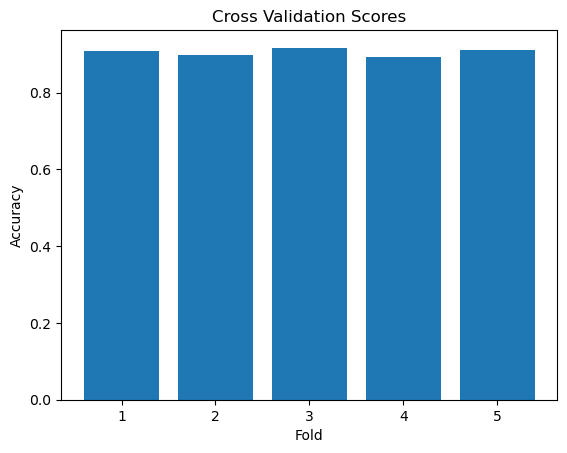

In [36]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(rf, X, y, cv=5)
print("Cross Validation Accuracy:", scores.mean())

# Visualization
plt.figure()
plt.bar(range(1,6), scores)
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("Cross Validation Scores")
plt.show()
